## Compare SHAP and LIME explanations by performing an in-depth statistical correlation analysis, manually quantifying consistency across methods, and identifying limitations in each approach for different feature types.

In [2]:
%pip install shap lime

  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
   ---------------------------------------- 0.0/751.9 kB ? eta -:--:--
   ---------------------------------------- 751.9/751.9 kB 7.8 MB/s  0:00:00
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283918 sha256=1362d36c3fd649e076a65209ac245a47280710899fa0d461e0e2875aa7c40deb
  Stored in directory: c:\users\admin\appdata\local\pip\cache\wheels\7c\04\5c\157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime

   ------------- -------------------------- 1/3 [shap]
   ------------- -------------------------- 1/3 [shap]
   ------------- -------------------------- 1/3 [shap]
   ------------- -------------------------- 1/3 [shap]

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import shap

from lime.lime_tabular import LimeTabularExplainer

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

from scipy.stats import pearsonr, spearmanr

print("All libraries imported successfully!")

All libraries imported successfully!


In [4]:
df = pd.read_csv("heart.csv")

print("Dataset Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("Missing Values:", df.isnull().sum().sum())

display(df.head())
display(df.describe())

Dataset Shape: (303, 14)
Columns: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal', 'target']
Missing Values: 0


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
count,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000,303.000000
mean,54.366337,0.683168,0.966997,131.623762,246.264026,0.148515,0.528053,149.646865,0.326733,1.039604,1.399340,0.729373,2.313531,0.544554
std,9.082101,0.466011,1.032052,17.538143,51.830751,0.356198,0.525860,22.905161,0.469794,1.161075,0.616226,1.022606,0.612277,0.498835
min,29.000000,0.000000,0.000000,94.000000,126.000000,0.000000,0.000000,71.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,47.500000,0.000000,0.000000,120.000000,211.000000,0.000000,0.000000,133.500000,0.000000,0.000000,1.000000,0.000000,2.000000,0.000000
50%,55.000000,1.000000,1.000000,130.000000,240.000000,0.000000,1.000000,153.000000,0.000000,0.800000,1.000000,0.000000,2.000000,1.000000
75%,61.000000,1.000000,2.000000,140.000000,274.500000,0.000000,1.000000,166.000000,1.000000,1.600000,2.000000,1.000000,3.000000,1.000000
max,77.000000,1.000000,3.000000,200.000000,564.000000,1.000000,2.000000,202.000000,1.000000,6.200000,2.000000,4.000000,3.000000,1.000000


In [5]:
print("Target Distribution:")
print(df["target"].value_counts())

print("\nTarget Percentage:")
print((df["target"].value_counts(normalize=True) * 100).round(2))

print("\nUnique Values in Each Feature:")
display(df.nunique().to_frame("Unique Values"))

print("\nDuplicate Rows:", df.duplicated().sum())

Target Distribution:
target
1    165
0    138
Name: count, dtype: int64

Target Percentage:
target
1    54.46
0    45.54
Name: proportion, dtype: float64

Unique Values in Each Feature:


,Unique Values
age,41
sex,2
cp,4
trestbps,49
chol,152
fbs,2
restecg,3
thalach,91
exang,2
oldpeak,40



Duplicate Rows: 1


In [6]:
X = df.drop("target", axis=1)
y = df["target"]

feature_names = X.columns.tolist()

categorical_columns = [
    "sex", "cp", "fbs", "restecg",
    "exang", "slope", "ca", "thal"
]

categorical_features = [
    X.columns.get_loc(col)
    for col in categorical_columns
]

categorical_names = {
    X.columns.get_loc("sex"): ["Female", "Male"],
    X.columns.get_loc("cp"): [
        "Type 0", "Type 1", "Type 2", "Type 3"
    ],
    X.columns.get_loc("fbs"): ["False", "True"],
    X.columns.get_loc("restecg"): [
        "Type 0", "Type 1", "Type 2"
    ],
    X.columns.get_loc("exang"): ["No", "Yes"],
    X.columns.get_loc("slope"): [
        "Type 0", "Type 1", "Type 2"
    ],
    X.columns.get_loc("ca"): [
        "0 vessels", "1 vessel", "2 vessels",
        "3 vessels", "4 vessels"
    ],
    X.columns.get_loc("thal"): [
        "Type 0", "Type 1", "Type 2", "Type 3"
    ]
}

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Samples:", len(X_train))
print("Testing Samples:", len(X_test))
print("Number of Features:", len(feature_names))

Training Samples: 242
Testing Samples: 61
Number of Features: 13


In [7]:
model = RandomForestClassifier(
    n_estimators=200,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print(classification_report(y_test, y_pred))

Accuracy: 0.8197
              precision    recall  f1-score   support

           0       0.95      0.64      0.77        28
           1       0.76      0.97      0.85        33

    accuracy                           0.82        61
   macro avg       0.85      0.81      0.81        61
weighted avg       0.85      0.82      0.81        61



In [8]:
sample = X_test.iloc[[0]]

actual_target = y_test.loc[sample.index].iloc[0]
predicted_target = model.predict(sample)[0]
disease_probability = model.predict_proba(sample)[0][
    list(model.classes_).index(1)
]

print("Actual Target:", actual_target)
print("Predicted Target:", predicted_target)
print("Predicted Probability for Class 1:",
      round(disease_probability, 4))

display(sample)

Actual Target: 0
Predicted Target: 0
Predicted Probability for Class 1: 0.175


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal
179,57,1,0,150,276,0,0,112,1,0.6,1,1,1


In [9]:
shap_explainer = shap.TreeExplainer(model)

raw_shap = shap_explainer.shap_values(sample)

if isinstance(raw_shap, list):
    shap_contributions = np.asarray(raw_shap[1]).reshape(-1)
else:
    raw_shap = np.asarray(raw_shap)

    if raw_shap.ndim == 3:
        if raw_shap.shape[1] == len(feature_names):
            shap_contributions = raw_shap[0, :, 1]
        else:
            shap_contributions = raw_shap[0, 1, :]
    else:
        shap_contributions = raw_shap.reshape(-1)

shap_result = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": shap_contributions,
    "SHAP Importance": np.abs(shap_contributions)
})

shap_result = shap_result.sort_values(
    "SHAP Importance",
    ascending=False
)

display(shap_result.round(4))

,Feature,SHAP Value,SHAP Importance
2,cp,-0.0965,0.0965
11,ca,-0.0794,0.0794
7,thalach,-0.0781,0.0781
8,exang,-0.0679,0.0679
9,oldpeak,0.0631,0.0631
10,slope,-0.0475,0.0475
12,thal,0.0377,0.0377
4,chol,-0.0370,0.0370
1,sex,-0.0269,0.0269
0,age,-0.0223,0.0223


In [10]:
lime_explainer = LimeTabularExplainer(
    training_data=X_train.to_numpy(),
    feature_names=feature_names,
    class_names=[str(c) for c in model.classes_],
    categorical_features=categorical_features,
    categorical_names=categorical_names,
    mode="classification",
    discretize_continuous=True,
    random_state=42
)

lime_explanation = lime_explainer.explain_instance(
    data_row=sample.iloc[0].to_numpy(),
    predict_fn=model.predict_proba,
    labels=[1],
    num_features=len(feature_names),
    num_samples=3000
)

lime_map = dict(lime_explanation.as_map()[1])

lime_contributions = np.array([
    lime_map.get(i, 0.0)
    for i in range(len(feature_names))
])

lime_result = pd.DataFrame({
    "Feature": feature_names,
    "LIME Value": lime_contributions,
    "LIME Importance": np.abs(lime_contributions)
})

lime_result = lime_result.sort_values(
    "LIME Importance",
    ascending=False
)

display(lime_result.round(4))

D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(


,Feature,LIME Value,LIME Importance
2,cp,-0.1842,0.1842
11,ca,-0.0943,0.0943
8,exang,-0.0880,0.0880
7,thalach,-0.0859,0.0859
1,sex,-0.0708,0.0708
9,oldpeak,0.0639,0.0639
4,chol,-0.0595,0.0595
10,slope,-0.0584,0.0584
12,thal,0.0395,0.0395
3,trestbps,-0.0388,0.0388


In [11]:
comparison = pd.DataFrame({
    "Feature": feature_names,
    "SHAP Value": shap_contributions,
    "LIME Value": lime_contributions
})

comparison["SHAP Importance"] = comparison["SHAP Value"].abs()
comparison["LIME Importance"] = comparison["LIME Value"].abs()

comparison["SHAP Rank"] = (
    comparison["SHAP Importance"]
    .rank(ascending=False, method="average")
)

comparison["LIME Rank"] = (
    comparison["LIME Importance"]
    .rank(ascending=False, method="average")
)

comparison = comparison.sort_values(
    "SHAP Importance",
    ascending=False
)

display(comparison.round(4))

,Feature,SHAP Value,LIME Value,SHAP Importance,LIME Importance,SHAP Rank,LIME Rank
2,cp,-0.0965,-0.1842,0.0965,0.1842,1.0,1.0
11,ca,-0.0794,-0.0943,0.0794,0.0943,2.0,2.0
7,thalach,-0.0781,-0.0859,0.0781,0.0859,3.0,4.0
8,exang,-0.0679,-0.0880,0.0679,0.0880,4.0,3.0
9,oldpeak,0.0631,0.0639,0.0631,0.0639,5.0,6.0
10,slope,-0.0475,-0.0584,0.0475,0.0584,6.0,8.0
12,thal,0.0377,0.0395,0.0377,0.0395,7.0,9.0
4,chol,-0.0370,-0.0595,0.0370,0.0595,8.0,7.0
1,sex,-0.0269,-0.0708,0.0269,0.0708,9.0,5.0
0,age,-0.0223,-0.0361,0.0223,0.0361,10.0,11.0


In [12]:
shap_imp = comparison["SHAP Importance"].to_numpy()
lime_imp = comparison["LIME Importance"].to_numpy()

if np.std(shap_imp) > 0 and np.std(lime_imp) > 0:
    pearson_corr, pearson_p = pearsonr(shap_imp, lime_imp)
    spearman_corr, spearman_p = spearmanr(shap_imp, lime_imp)

    print("Pearson Correlation:", round(pearson_corr, 4))
    print("Pearson P-value:", round(pearson_p, 4))

    print("Spearman Correlation:", round(spearman_corr, 4))
    print("Spearman P-value:", round(spearman_p, 4))
else:
    print("Correlation cannot be calculated because importance values are constant.")

Pearson Correlation: 0.8538
Pearson P-value: 0.0002
Spearman Correlation: 0.9066
Spearman P-value: 0.0


In [13]:
k = 5

shap_top = set(
    comparison.nlargest(k, "SHAP Importance")["Feature"]
)

lime_top = set(
    comparison.nlargest(k, "LIME Importance")["Feature"]
)

common_features = shap_top.intersection(lime_top)
union_features = shap_top.union(lime_top)

jaccard_score = len(common_features) / len(union_features)

print("SHAP Top 5:", sorted(shap_top))
print("LIME Top 5:", sorted(lime_top))
print("Common Features:", sorted(common_features))
print("Common Feature Count:", len(common_features))
print("Jaccard Score:", round(jaccard_score, 4))
print("Consistency Percentage:", round(jaccard_score * 100, 2), "%")

SHAP Top 5: ['ca', 'cp', 'exang', 'oldpeak', 'thalach']
LIME Top 5: ['ca', 'cp', 'exang', 'sex', 'thalach']
Common Features: ['ca', 'cp', 'exang', 'thalach']
Common Feature Count: 4
Jaccard Score: 0.6667
Consistency Percentage: 66.67 %


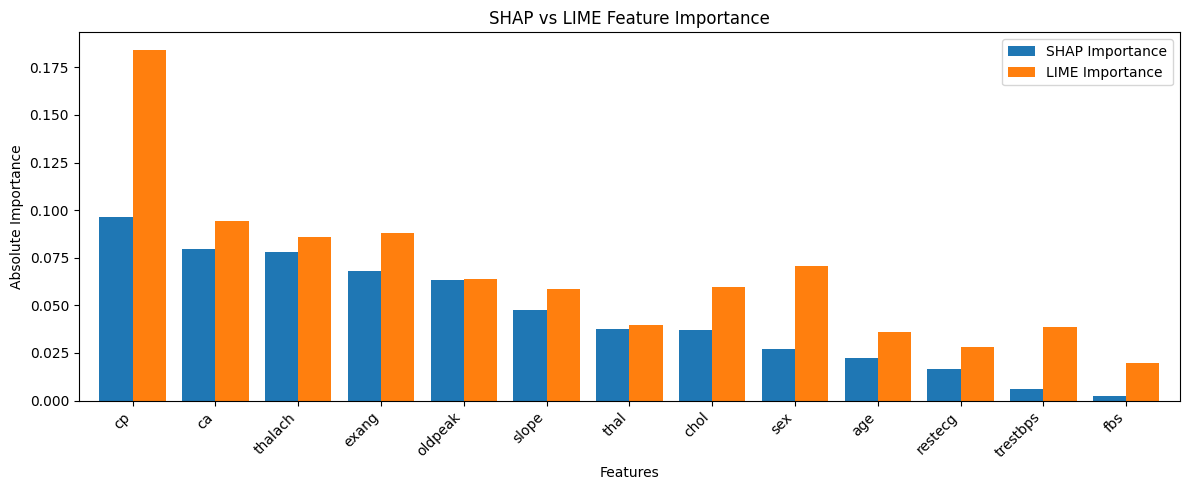

In [14]:
plot_data = comparison.set_index("Feature")[
    ["SHAP Importance", "LIME Importance"]
]

plot_data.plot(
    kind="bar",
    figsize=(12, 5),
    width=0.8
)

plt.title("SHAP vs LIME Feature Importance")
plt.xlabel("Features")
plt.ylabel("Absolute Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [15]:
def get_shap_values(row):
    values = shap_explainer.shap_values(row)

    if isinstance(values, list):
        return np.asarray(values[1]).reshape(-1)

    values = np.asarray(values)

    if values.ndim == 3:
        if values.shape[1] == len(feature_names):
            return values[0, :, 1]
        return values[0, 1, :]

    return values.reshape(-1)


shap_all = []
lime_all = []
local_spearman = []

for _, row in X_test.head(50).iterrows():
    row_df = row.to_frame().T

    sv = get_shap_values(row_df)

    explanation = lime_explainer.explain_instance(
        data_row=row.to_numpy(),
        predict_fn=model.predict_proba,
        labels=[1],
        num_features=len(feature_names),
        num_samples=1500
    )

    lime_map = dict(explanation.as_map()[1])

    lv = np.array([
        lime_map.get(i, 0.0)
        for i in range(len(feature_names))
    ])

    shap_all.append(np.abs(sv))
    lime_all.append(np.abs(lv))

    if np.std(sv) > 0 and np.std(lv) > 0:
        local_spearman.append(
            spearmanr(np.abs(sv), np.abs(lv)).statistic
        )

mean_shap = np.mean(shap_all, axis=0)
mean_lime = np.mean(lime_all, axis=0)

aggregate_comparison = pd.DataFrame({
    "Feature": feature_names,
    "Mean SHAP Importance": mean_shap,
    "Mean LIME Importance": mean_lime
})

aggregate_comparison["SHAP Rank"] = (
    aggregate_comparison["Mean SHAP Importance"]
    .rank(ascending=False)
)

aggregate_comparison["LIME Rank"] = (
    aggregate_comparison["Mean LIME Importance"]
    .rank(ascending=False)
)

display(
    aggregate_comparison.sort_values(
        "Mean SHAP Importance",
        ascending=False
    ).round(4)
)

if np.std(mean_shap) > 0 and np.std(mean_lime) > 0:
    print(
        "Aggregate Pearson:",
        round(pearsonr(mean_shap, mean_lime).statistic, 4)
    )

    print(
        "Aggregate Spearman:",
        round(spearmanr(mean_shap, mean_lime).statistic, 4)
    )

if local_spearman:
    print(
        "Mean Local Spearman:",
        round(np.mean(local_spearman), 4)
    )

D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Softwares\Anaconda\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but RandomForestClassifier was fitted with feature names
  warnings.warn(
D:\Softwar

,Feature,Mean SHAP Importance,Mean LIME Importance,SHAP Rank,LIME Rank
2,cp,0.1105,0.1544,1.0,2.0
12,thal,0.0940,0.1592,2.0,1.0
11,ca,0.0788,0.1343,3.0,3.0
9,oldpeak,0.0564,0.0704,4.0,5.0
7,thalach,0.0525,0.0574,5.0,8.0
8,exang,0.0508,0.0832,6.0,4.0
10,slope,0.0422,0.0666,7.0,7.0
1,sex,0.0309,0.0671,8.0,6.0
4,chol,0.0285,0.0408,9.0,9.0
0,age,0.0251,0.0258,10.0,11.0


Aggregate Pearson: 0.9652
Aggregate Spearman: 0.9396
Mean Local Spearman: 0.8314


In [16]:
limitations = pd.DataFrame({
    "Feature Type": [
        "Numerical",
        "Categorical",
        "Ordinal",
        "Correlated Features",
        "Small Dataset"
    ],
    "SHAP Limitation": [
        "Attribution depends on background distribution and model.",
        "Integer encoding may be mistaken for numeric relationships.",
        "May not preserve meaningful category order.",
        "Importance may be shared among correlated features.",
        "Explanations depend on model quality and available data."
    ],
    "LIME Limitation": [
        "Perturbed values may be unrealistic.",
        "Perturbations may create invalid category combinations.",
        "Local model may not respect category order.",
        "Local coefficients may change with sampling.",
        "Local surrogate may be unstable with limited data."
    ]
})

display(limitations)

,Feature Type,SHAP Limitation,LIME Limitation
0,Numerical,Attribution depends on background distribution...,Perturbed values may be unrealistic.
1,Categorical,Integer encoding may be mistaken for numeric r...,Perturbations may create invalid category comb...
2,Ordinal,May not preserve meaningful category order.,Local model may not respect category order.
3,Correlated Features,Importance may be shared among correlated feat...,Local coefficients may change with sampling.
4,Small Dataset,Explanations depend on model quality and avail...,Local surrogate may be unstable with limited d...


In [17]:
print("SHAP vs LIME Analysis Summary")
print("-" * 35)
print("Model Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Top Features in Common:", sorted(common_features))
print("Jaccard Consistency:", round(jaccard_score, 4))

if np.std(shap_imp) > 0 and np.std(lime_imp) > 0:
    print("Pearson Correlation:", round(pearson_corr, 4))
    print("Spearman Correlation:", round(spearman_corr, 4))

print("Patients Analysed:", len(shap_all))

SHAP vs LIME Analysis Summary
-----------------------------------
Model Accuracy: 0.8197
Top Features in Common: ['ca', 'cp', 'exang', 'thalach']
Jaccard Consistency: 0.6667
Pearson Correlation: 0.8538
Spearman Correlation: 0.9066
Patients Analysed: 50
